# Meta-learning: block-transition plateau across sessions

**Question.** After a block transition (Short→Long block or Long→Short block), how many trials does it take performance to reach a stable plateau — and does that number shrink across training sessions (early vs. late), separately for the two trial types (Long-ISI vs Short-ISI trials) that make up each block?

**Alignment.** Trial 0 for every transition is the *adjusted* transition point used elsewhere in this codebase (`adjusted_block_start` in `block_sequence_epoch_analysis.py` / the pooled-average notebook): a formal `block_type` switch is walked backward over any terminal run of rare trials belonging to the *previous* block, so trial 0 is guaranteed to never be preceded by a rare trial.

**Trial-type split.** Within the entered block, each trial is tagged `Long trial` (`trial_type == 2`) or `Short trial` (`trial_type == 1`) and indexed by its own *occurrence* count since the transition (the 1st Long trial after the transition, the 2nd, ...), not by raw trial position — one type is common (~77% of trials) and the other rare (~23%) within a block, so raw-position indexing would make the rare type's post-transition curve extremely sparse.

**Plateau metrics** (both computed per transition x trial-type-class, then summarized per session):
1. **Trial(occurrence)-to-criterion** — first occurrence where a *causal, full* rolling-window mean of `correct` (window = 2 or 3 trials, both tested) reaches a criterion accuracy (0.6/0.7/0.75/0.8 swept for robustness; 0.7 with window 3 is primary). Using a full window (not an expanding one) matters: with a 1-trial window, a single lucky correct trial would trivially satisfy "reached criterion," which is not what "N trials above criterion" is supposed to mean.
2. **Exponential time constant tau** — a saturating exponential `a*(1-exp(-x/tau))+b` fit to the occurrence-indexed accuracy curve pooled across a session's transitions of that condition; a threshold-free cross-check on the trial-to-criterion metric. Fits with R^2 < 0.15 (common when a session has very few transitions of a condition) are excluded from the tau figures.

**Session axis.** `subject_session_idx` (1..N, chronological, verified against `session_date`) is used as the training-session axis. Figures follow this codebase's standard layout: row 0 = all subjects pooled, rows 1-4 = each subject individually — directly giving both the pooled and per-subject views.

Exponential tau: excluded 51% of session-condition fits with R^2 < 0.15 (poor/degenerate fits, common with sparse per-session data).


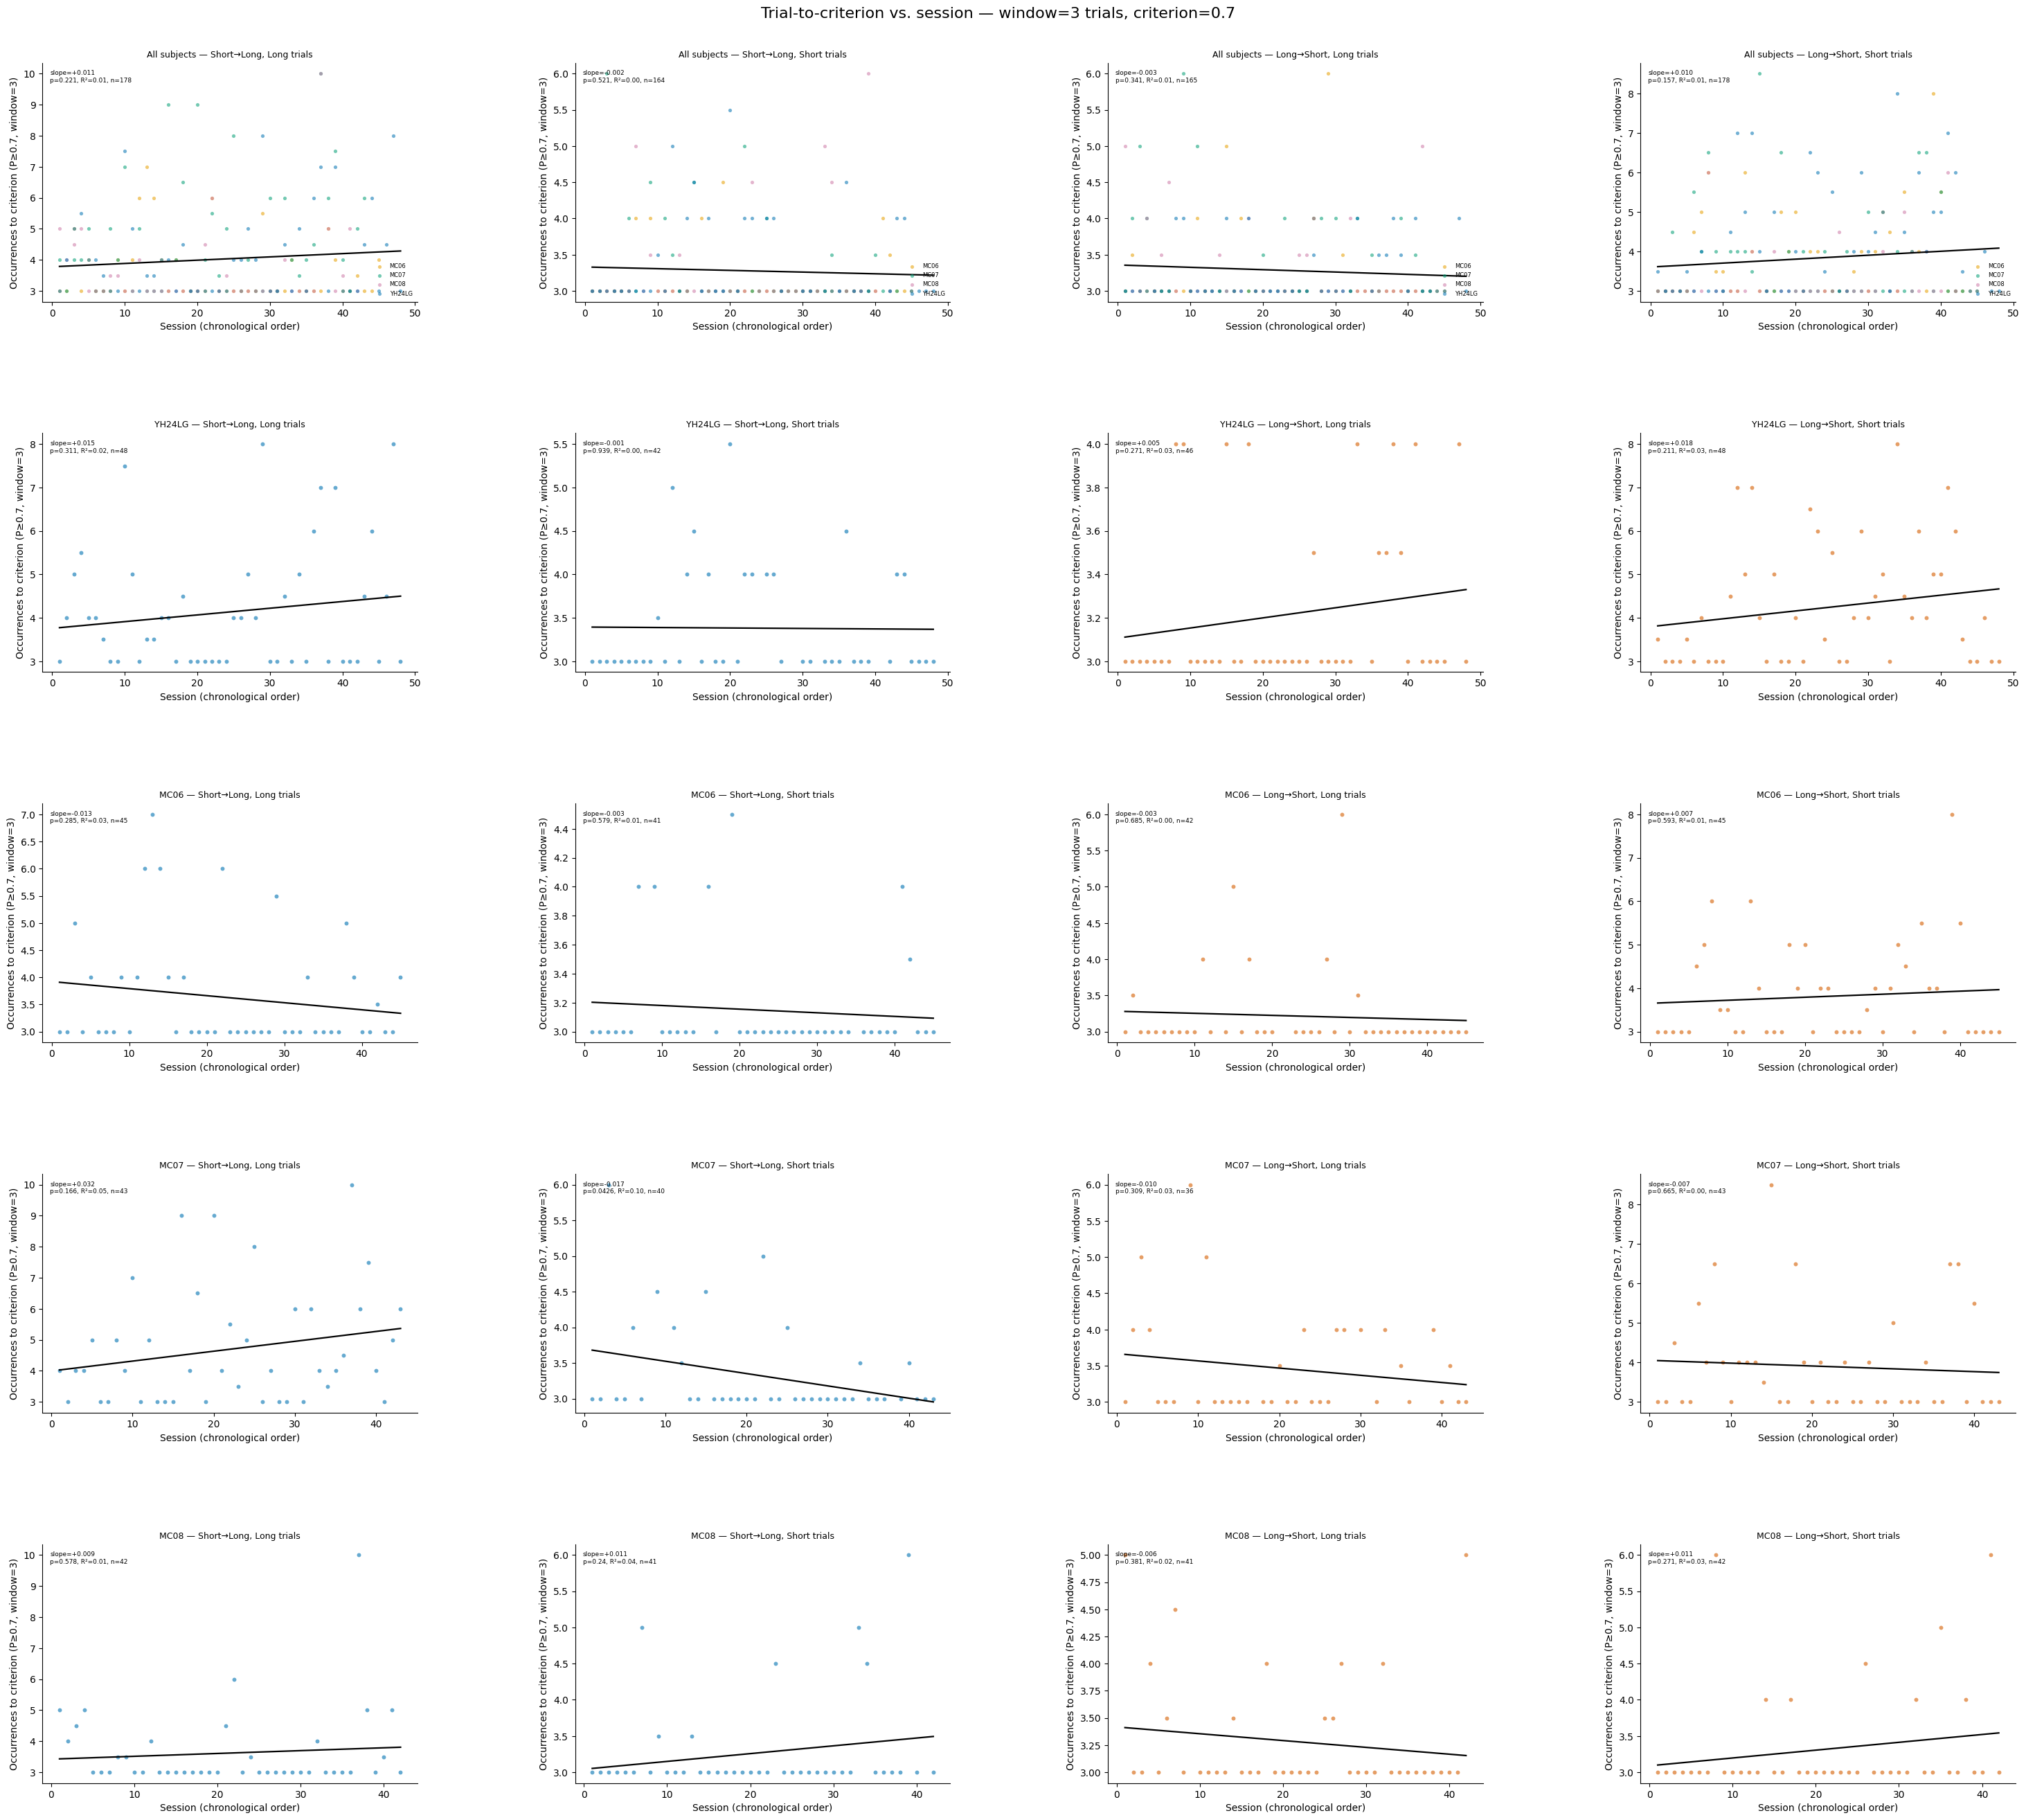

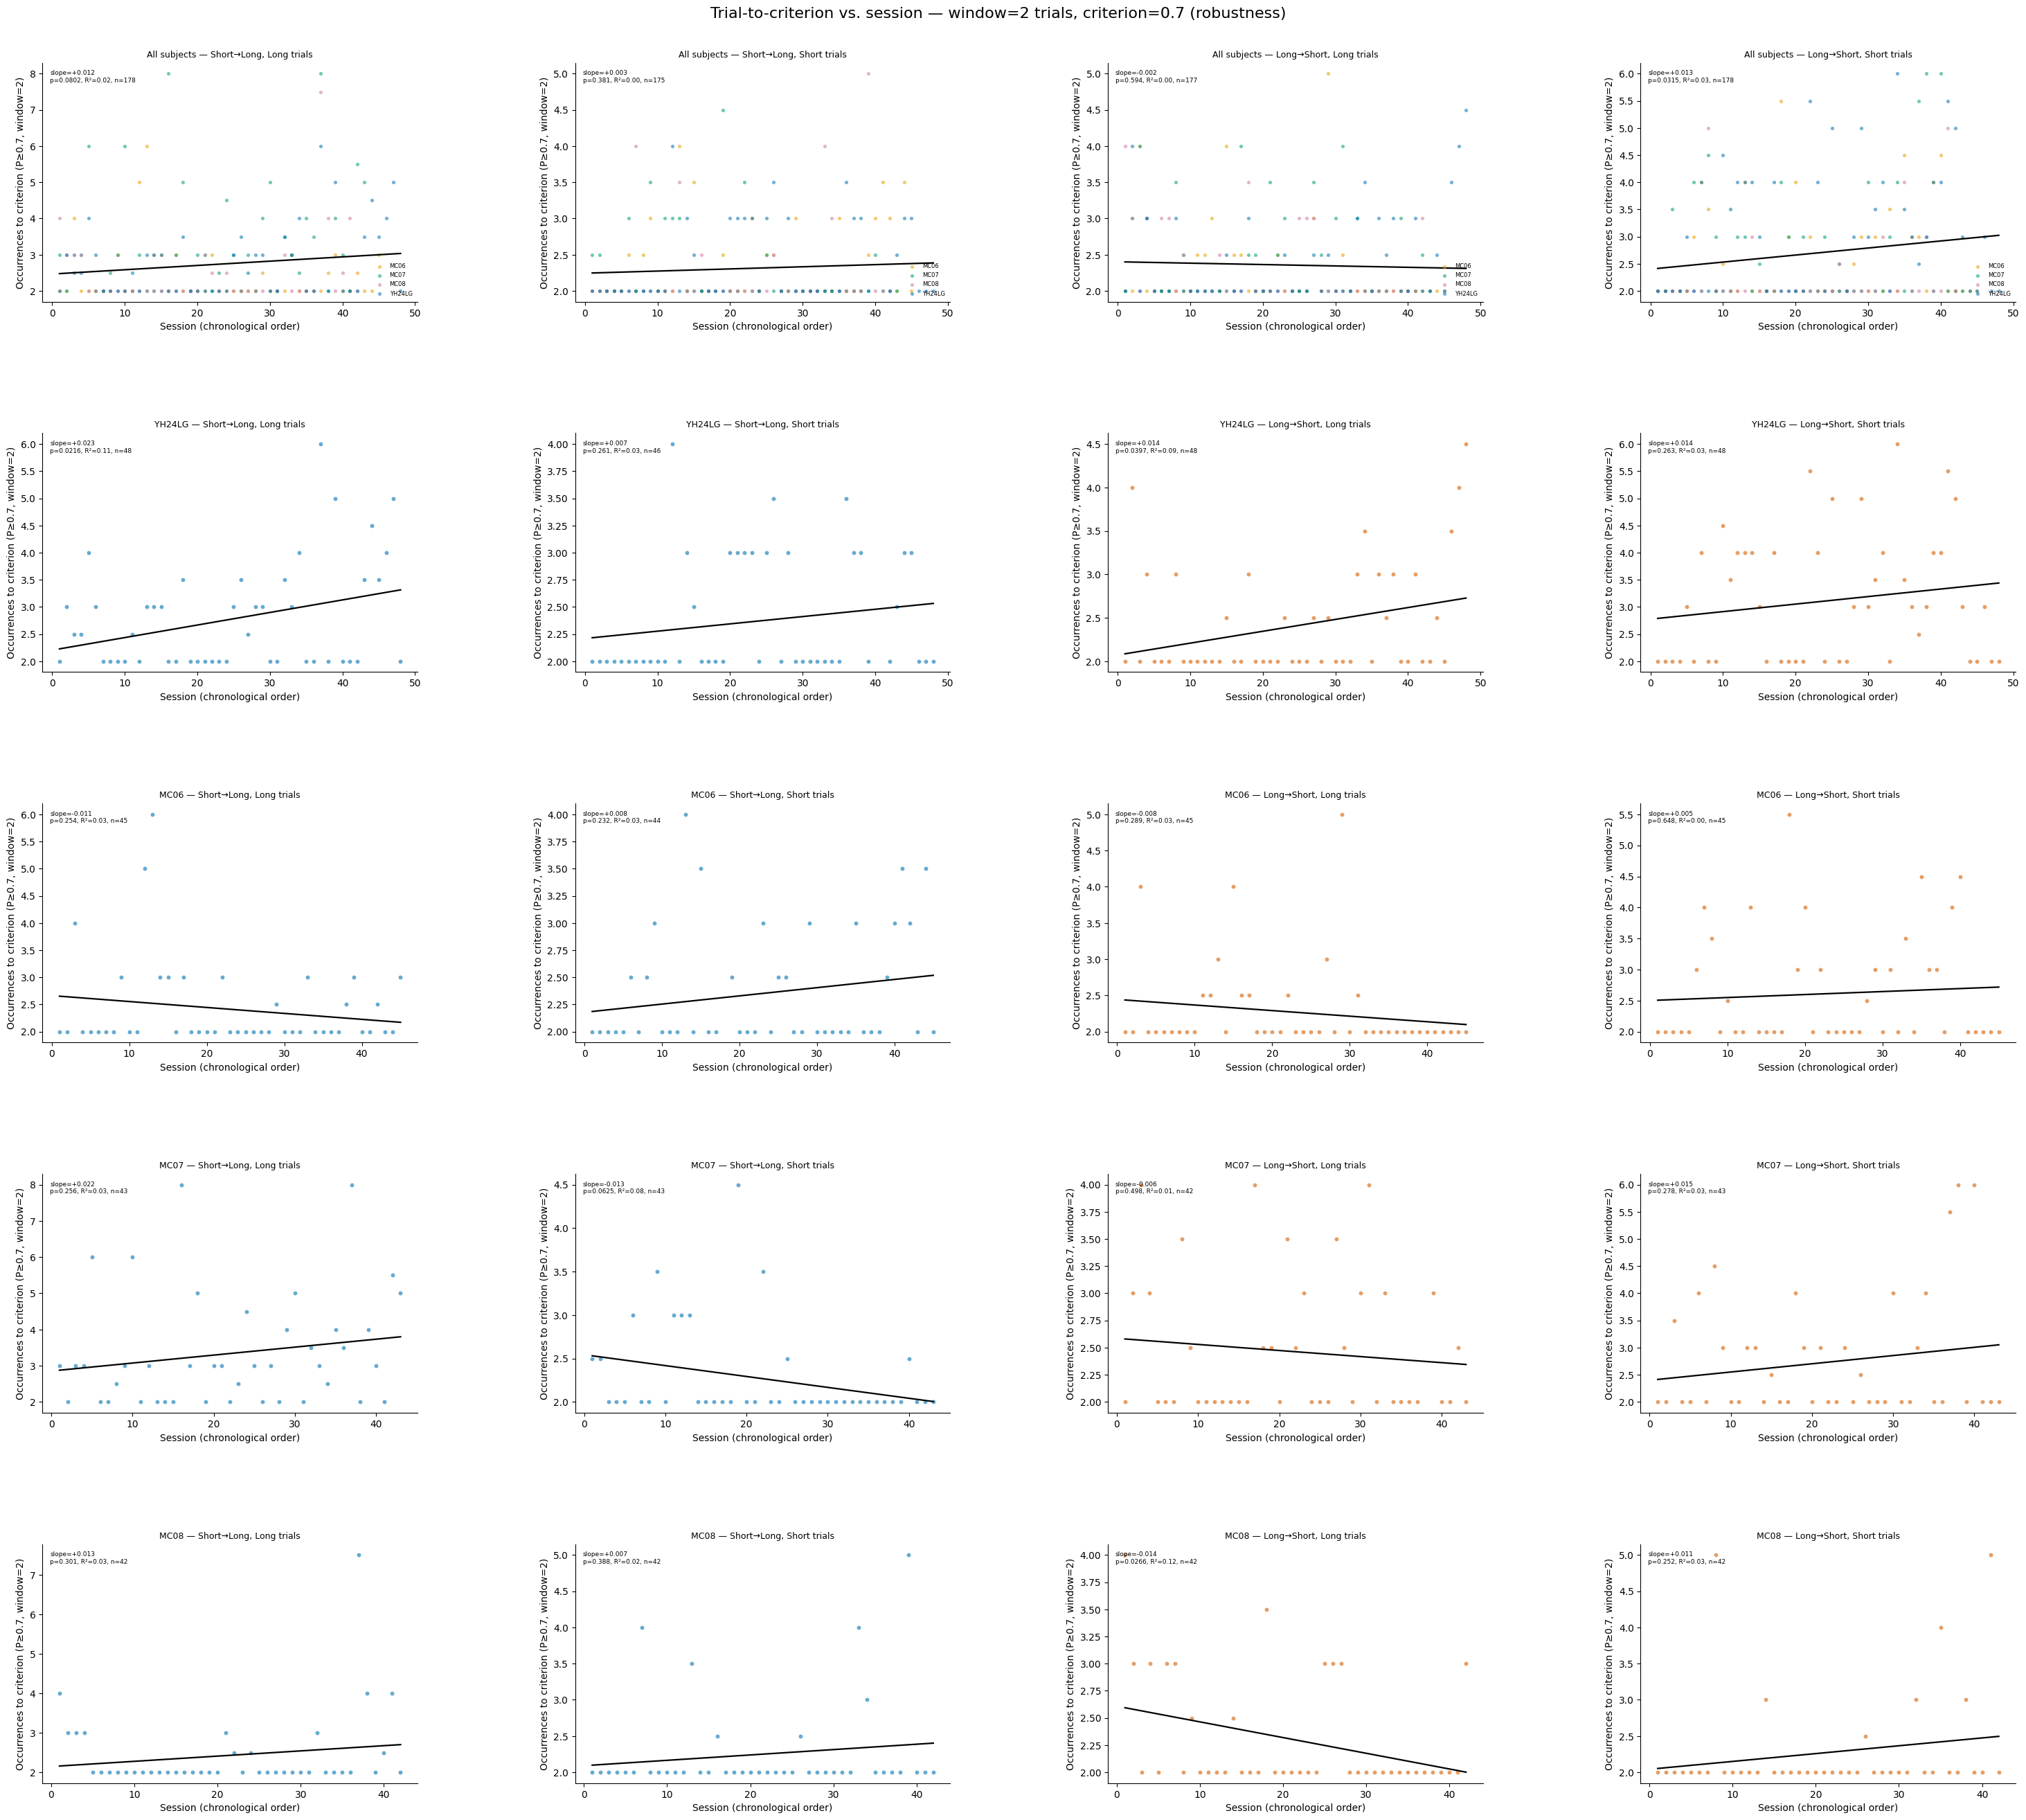

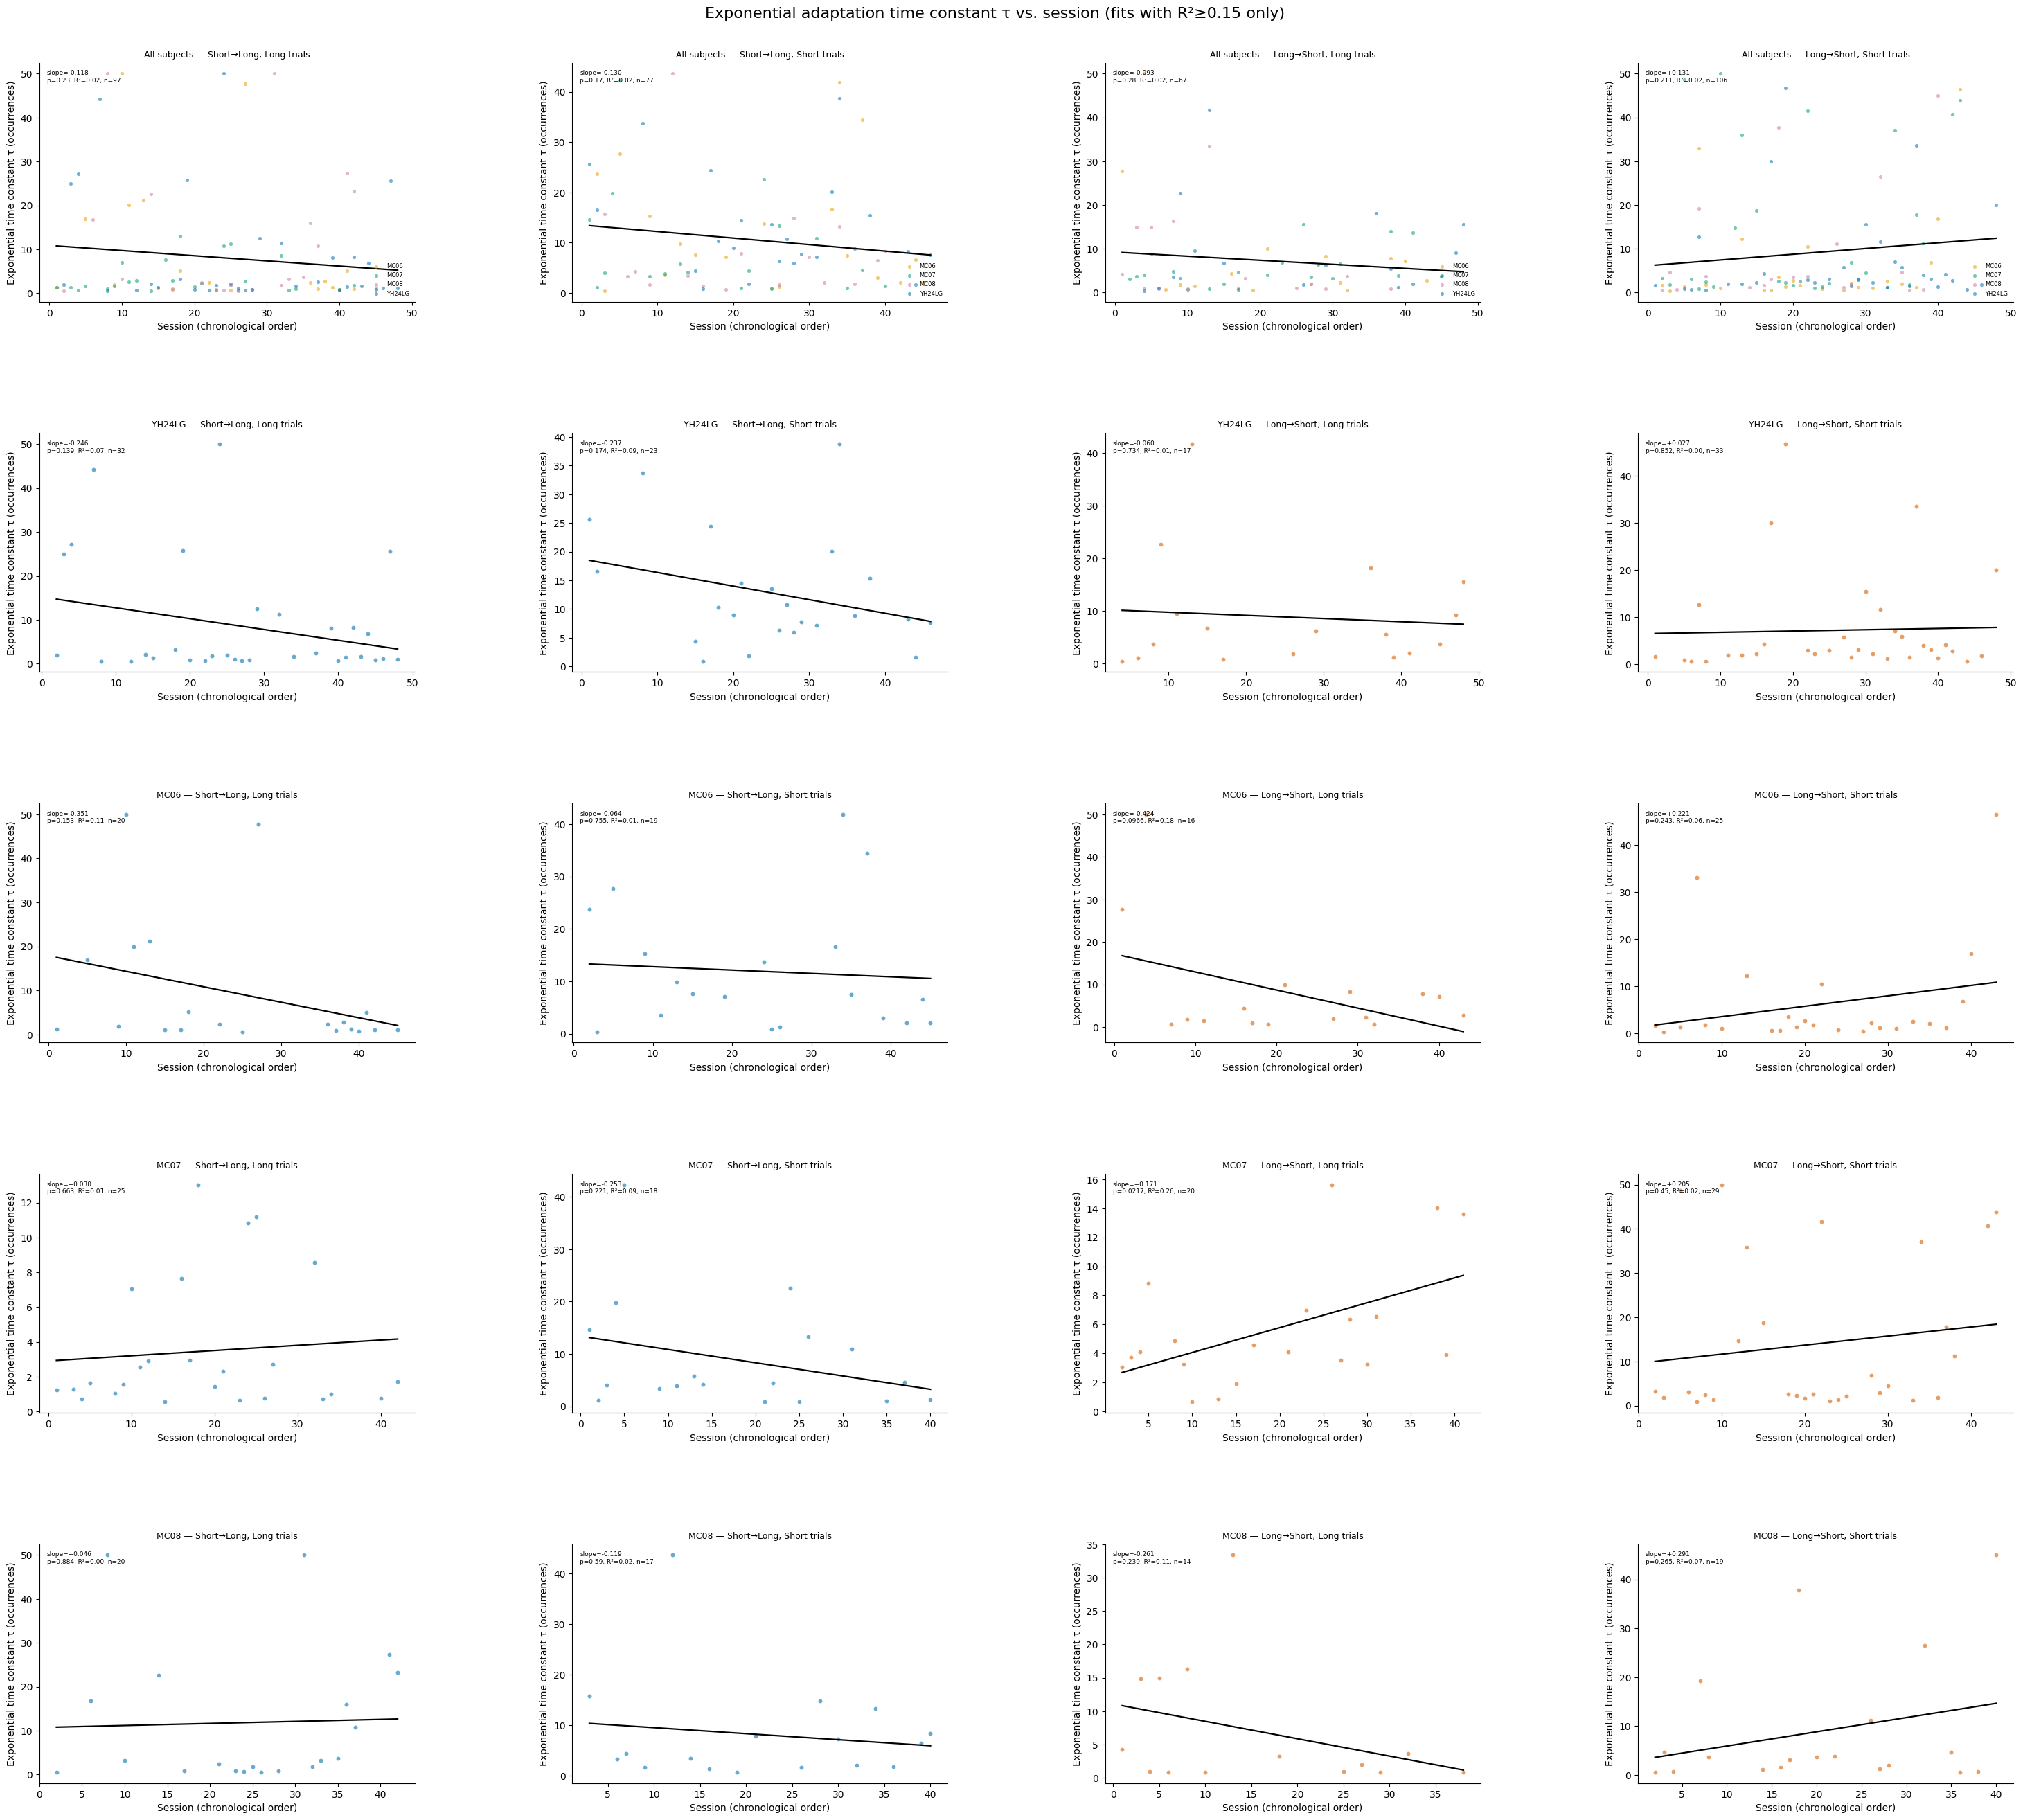

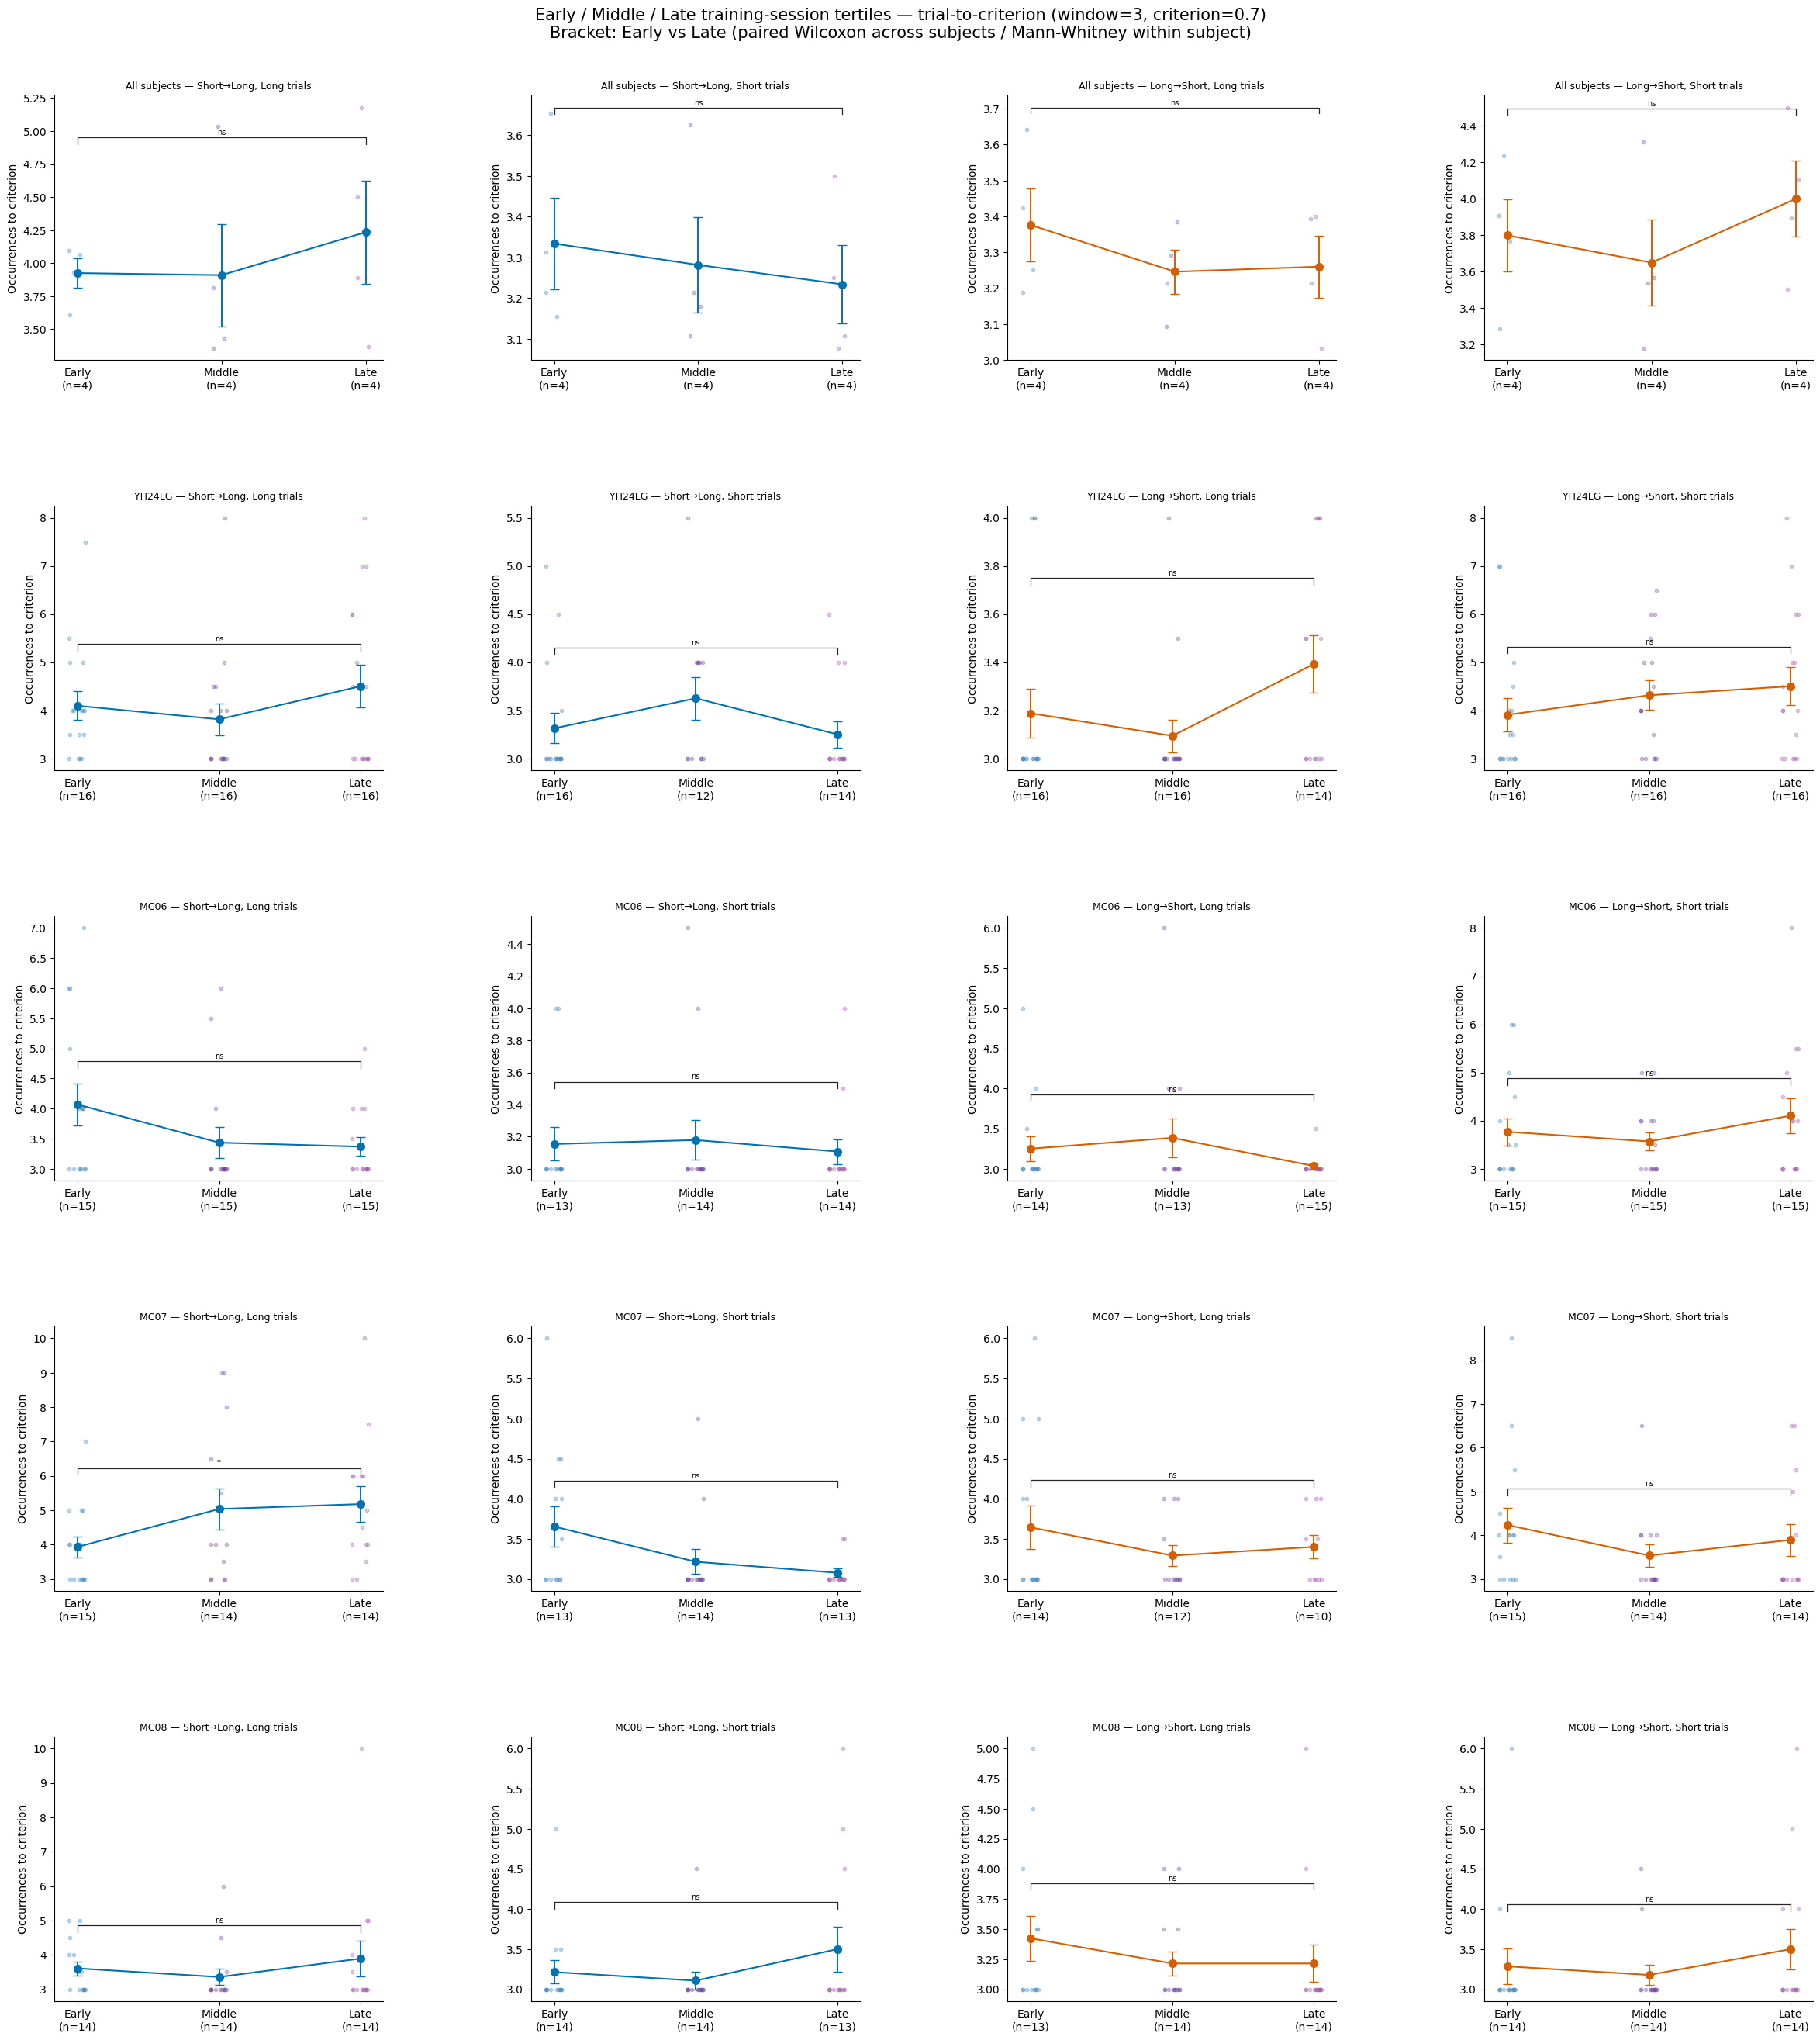

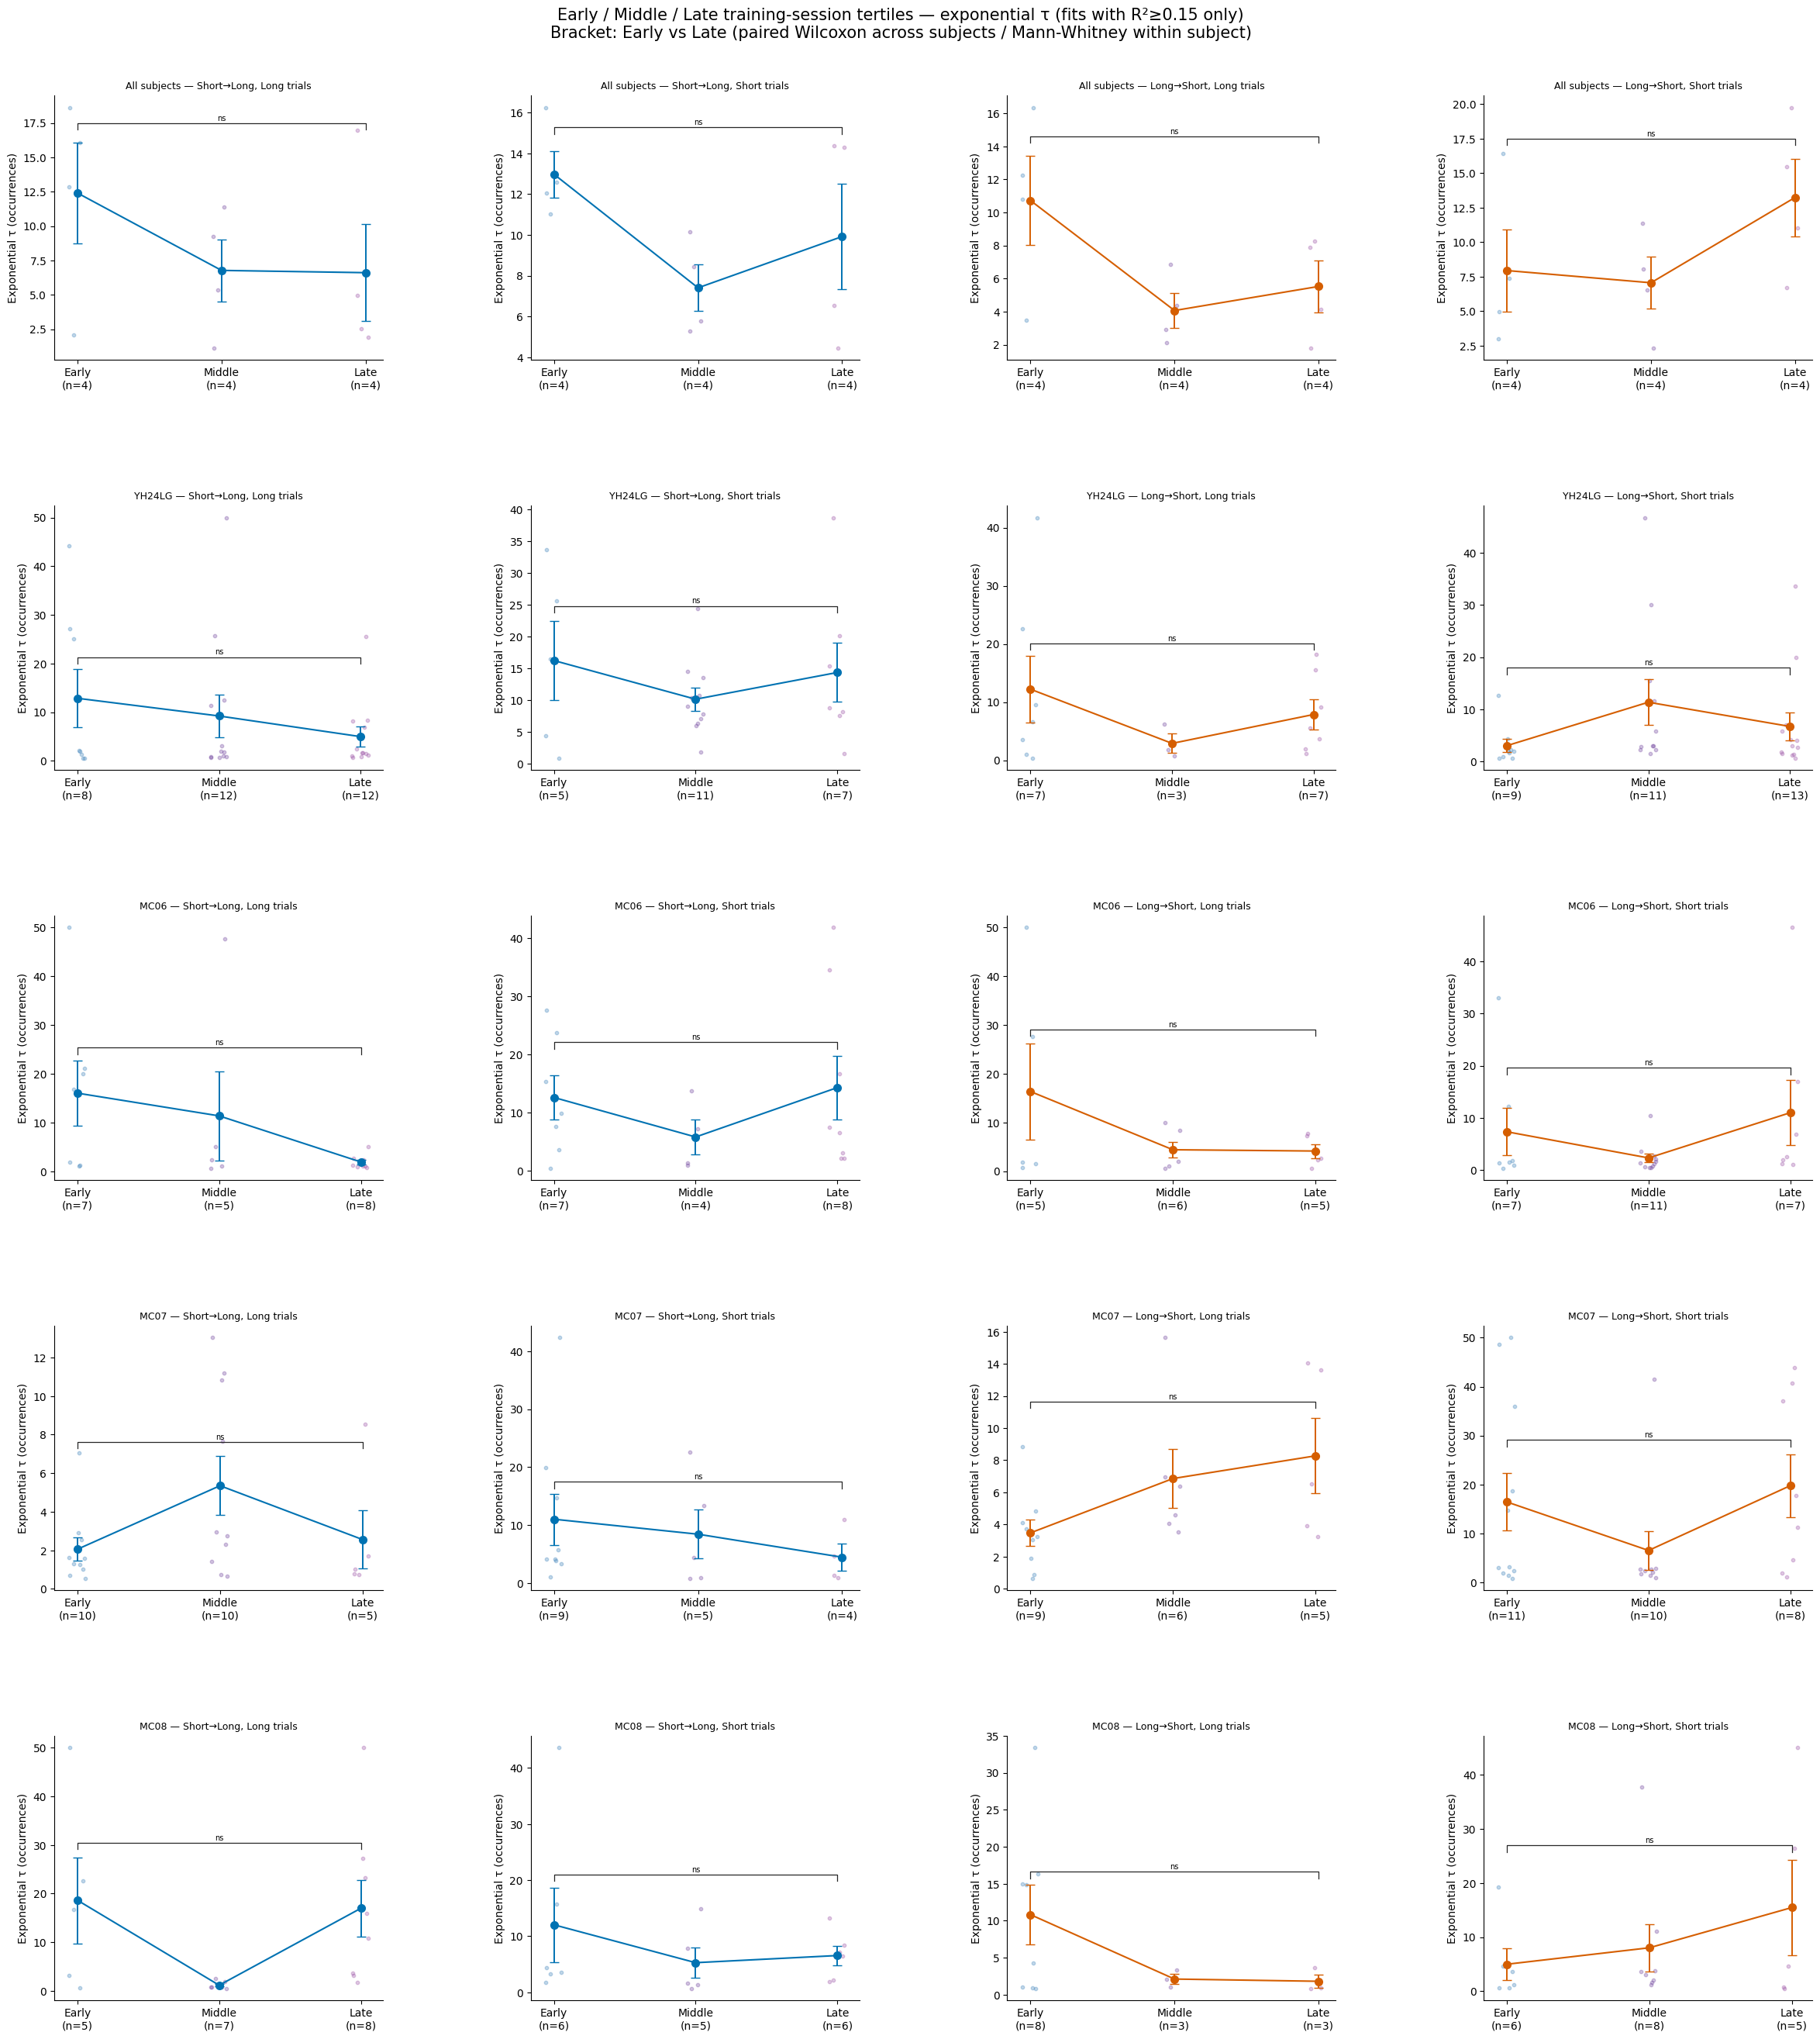

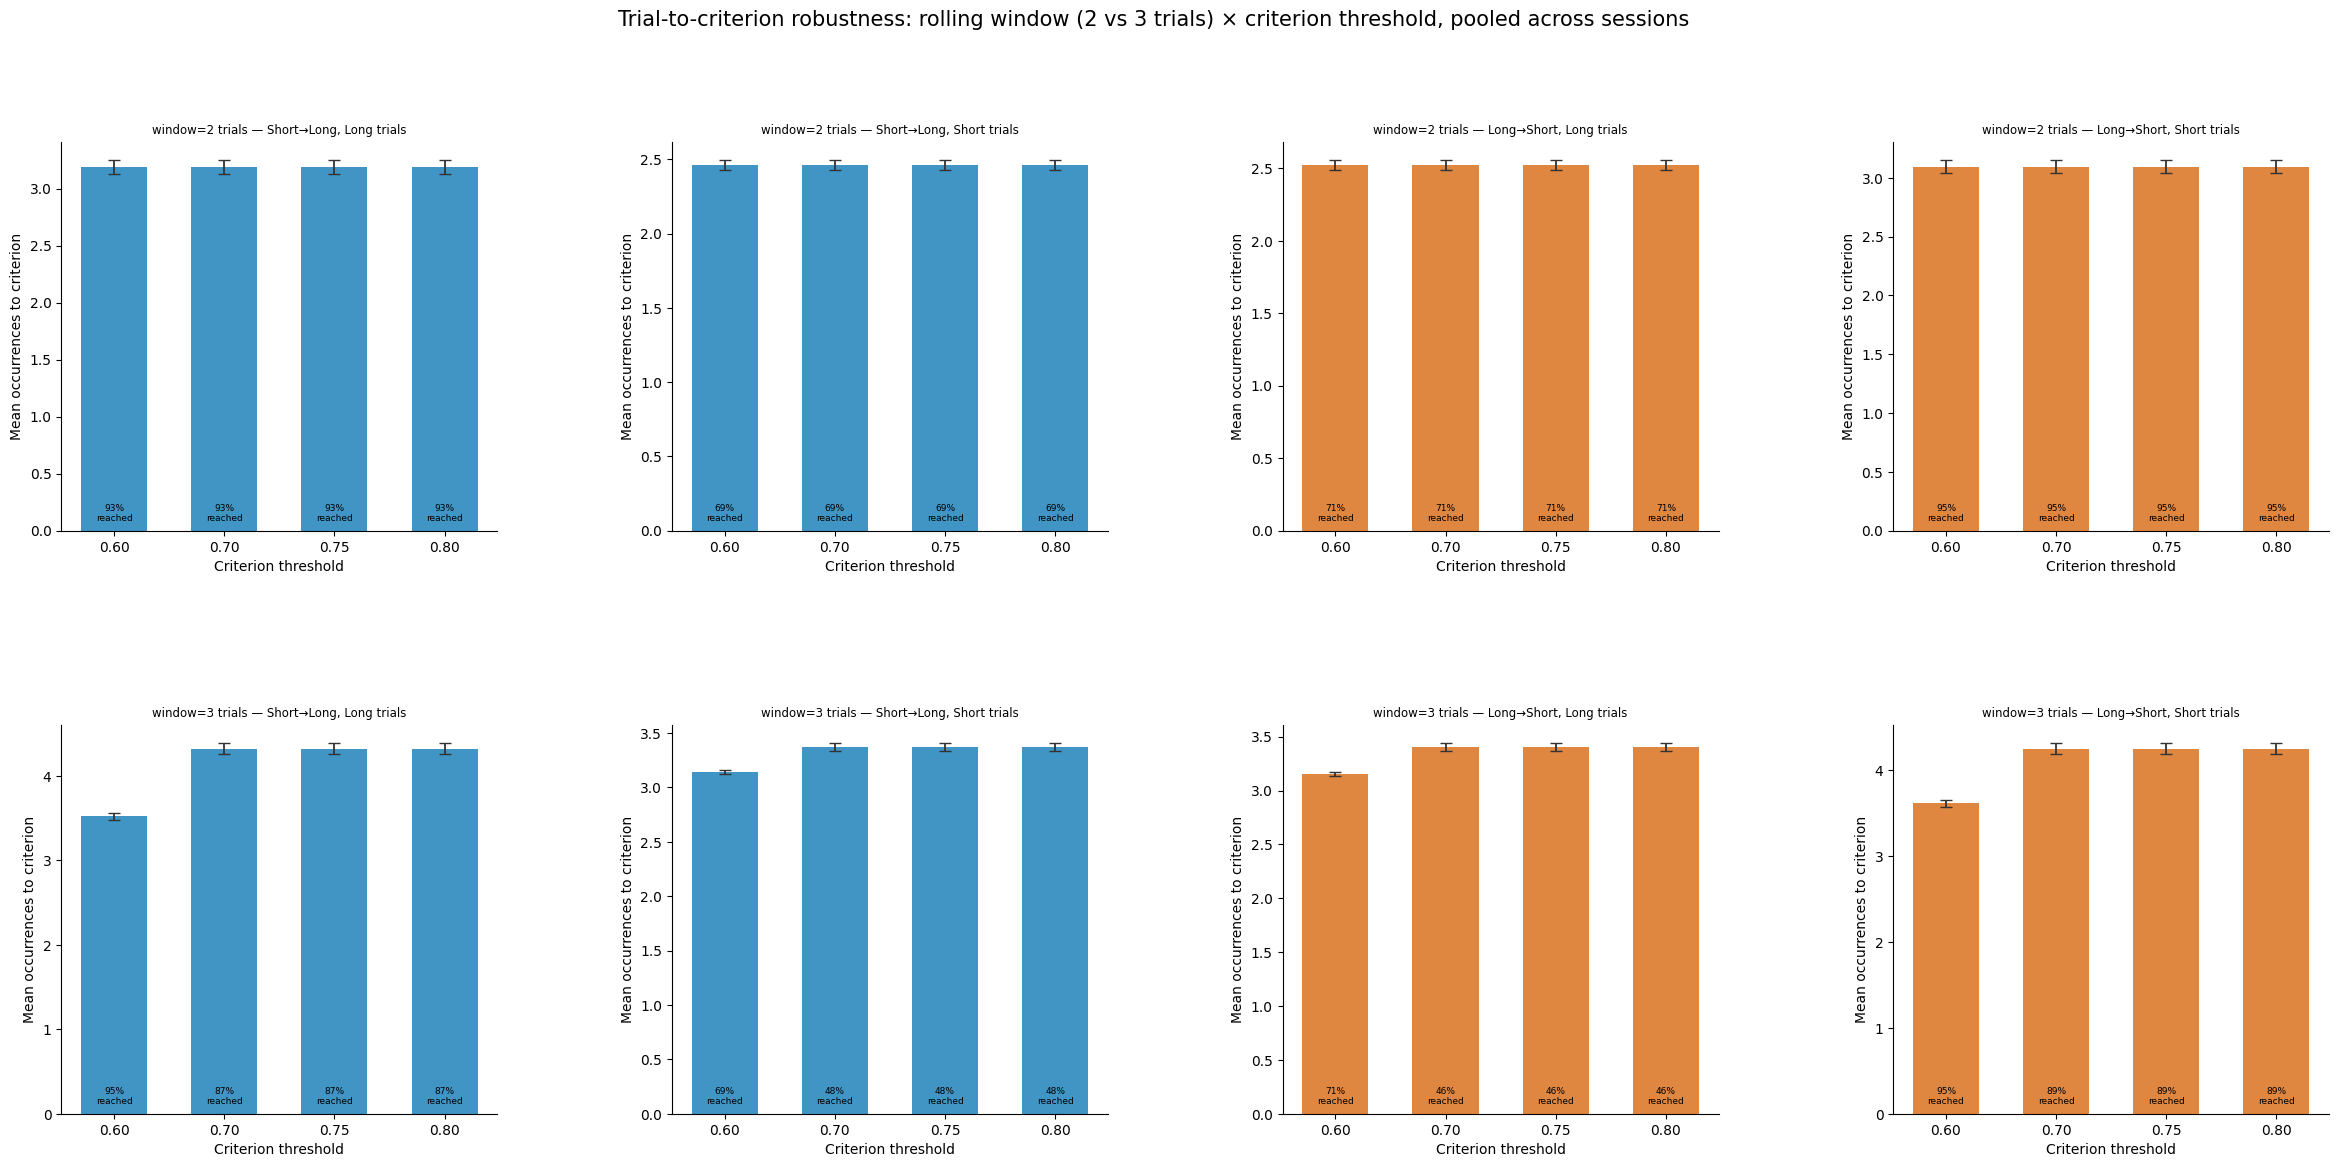

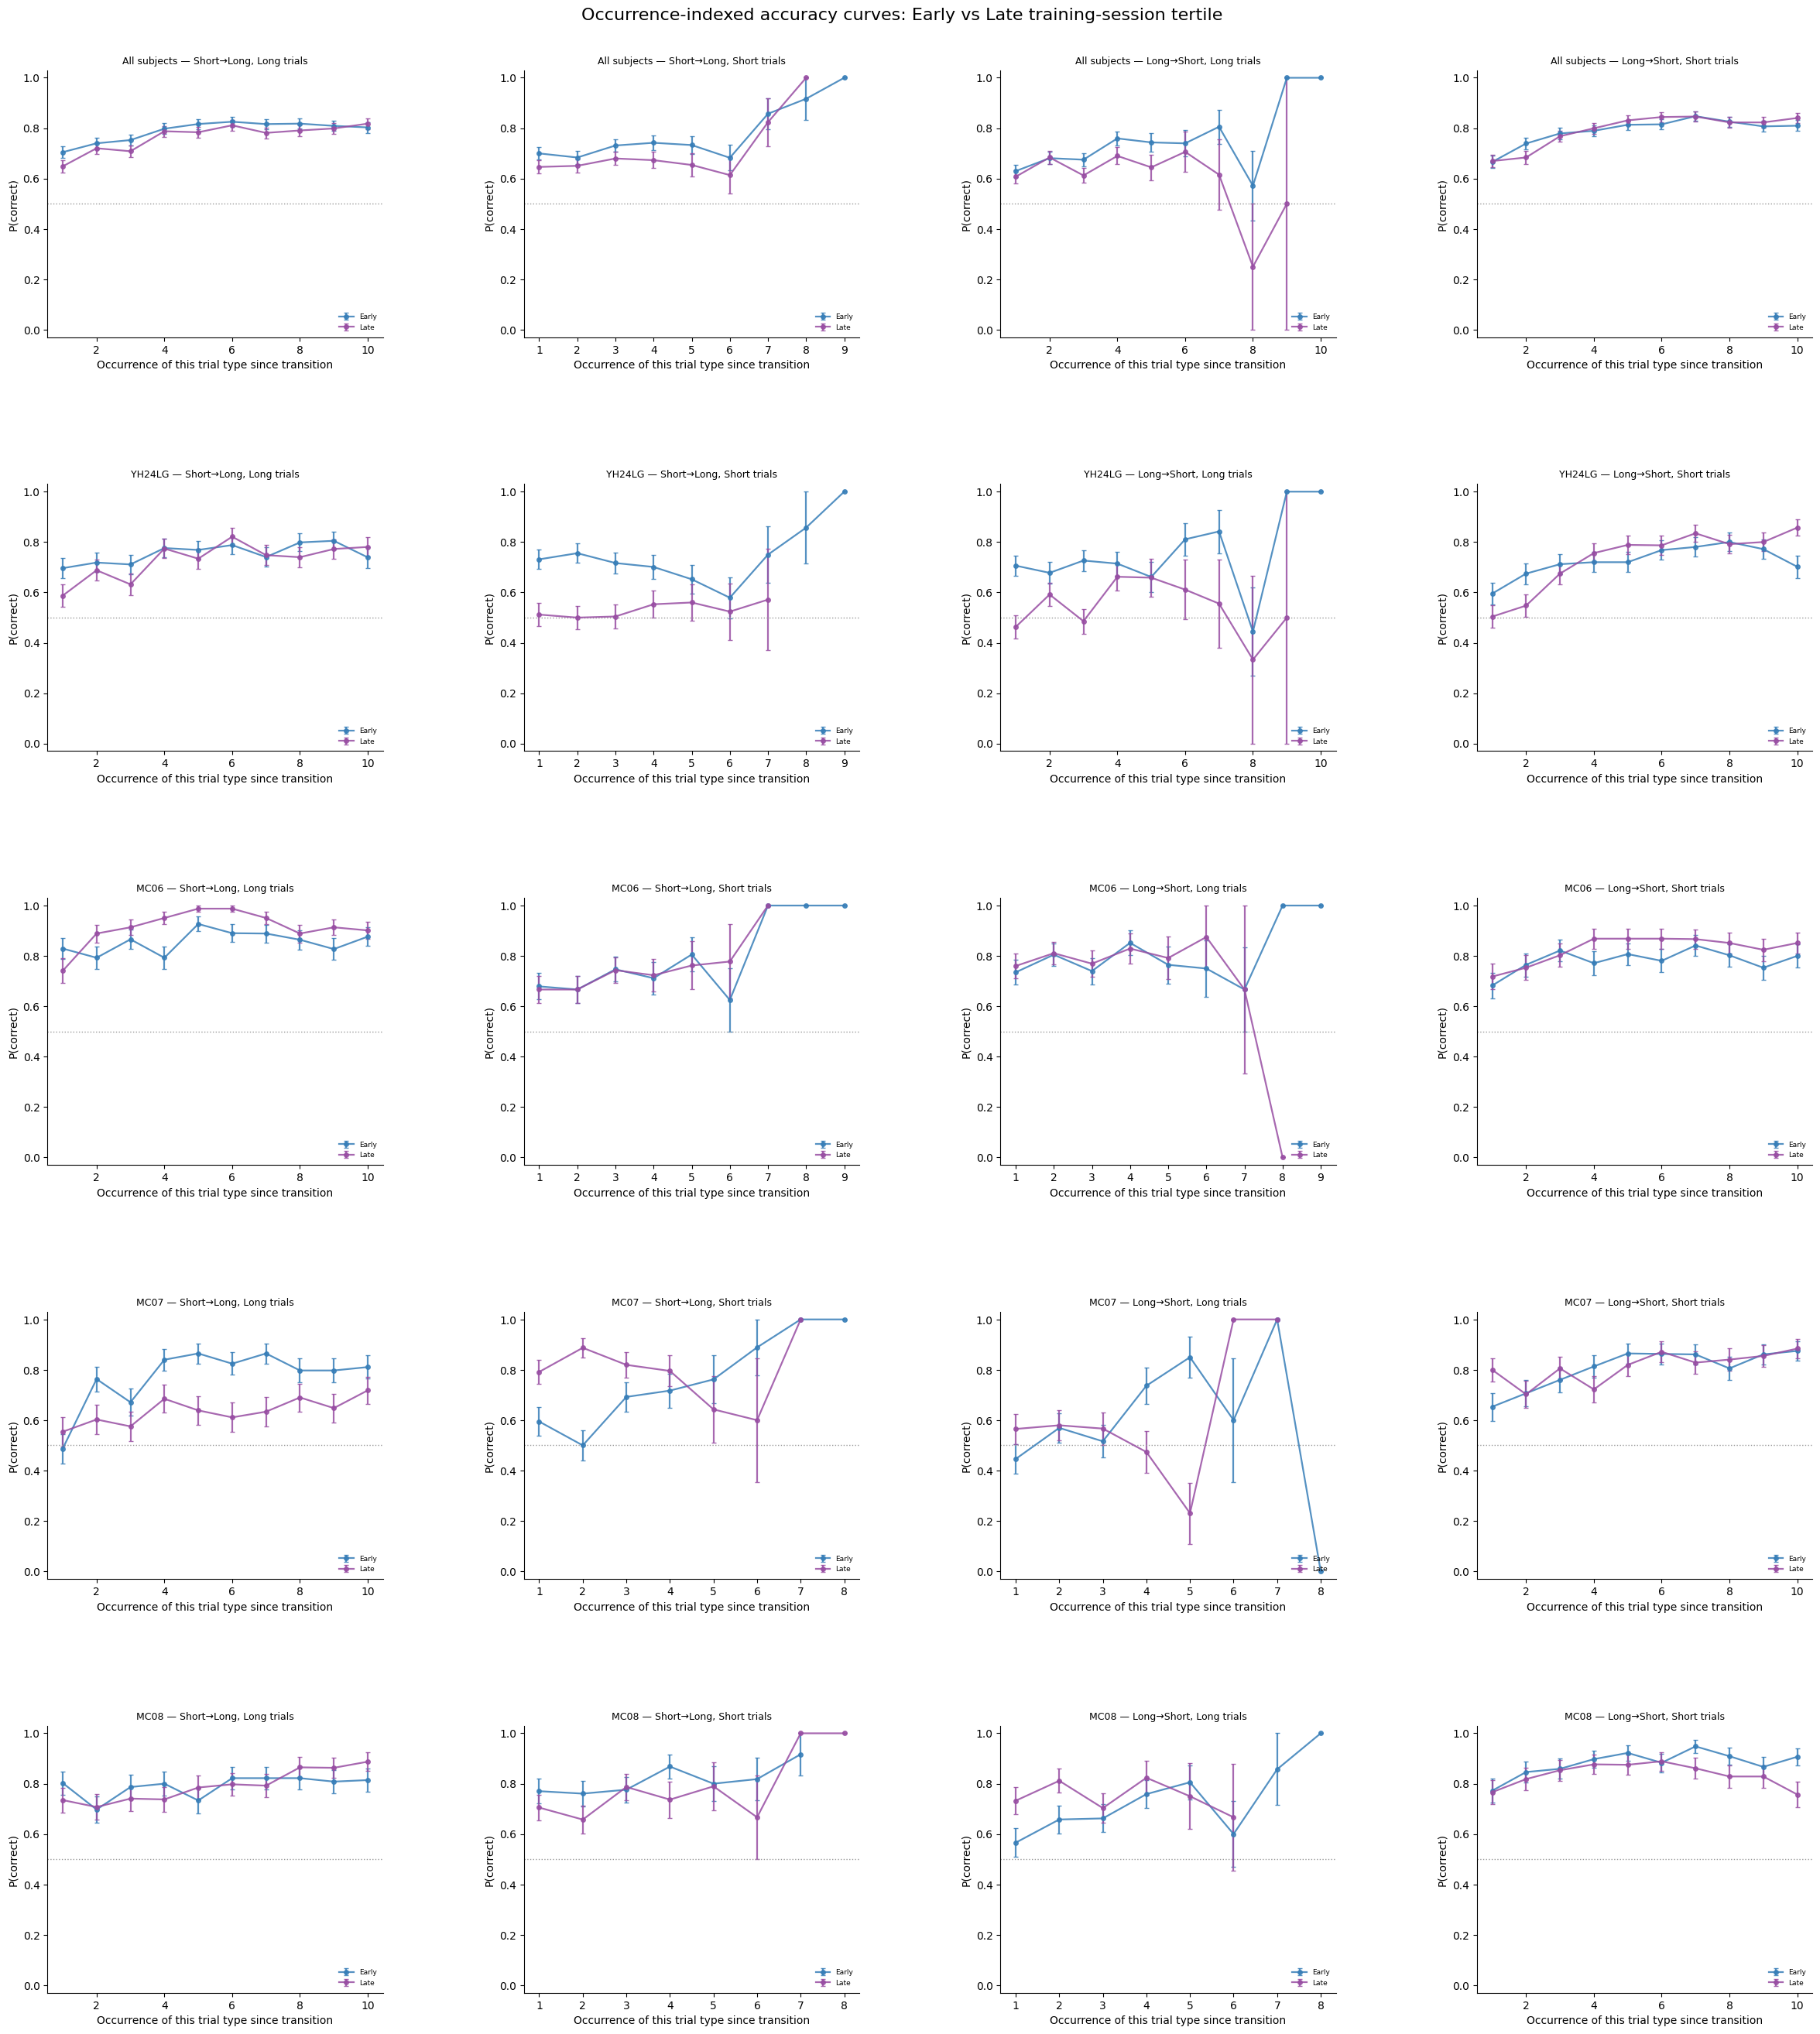

Saved: /home/ihsan/Desktop/data/Georgia_Tech/2AFC/Codes/Behavior/New_version/meta_learning_transition_plateau.pdf


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt

import meta_learning_transition_analysis as meta

DATA_PATH = Path('all_subjects_final_data.csv')
OUTPUT_PATH = Path('meta_learning_transition_plateau.pdf')

result = meta.run(data_path=DATA_PATH, output_path=OUTPUT_PATH, show=True)
print(f"Saved: {result['output_path'].resolve()}")

## Output pages

1. Trial-to-criterion vs. session — window=3, criterion=0.7 (primary)
2. Trial-to-criterion vs. session — window=2, criterion=0.7 (robustness)
3. Exponential tau vs. session (R^2>=0.15 fits only)
4. Early/Middle/Late session-tertile summary — trial-to-criterion, with Early-vs-Late significance bracket (paired Wilcoxon across subjects for the pooled row, Mann-Whitney within subject for the individual rows)
5. Early/Middle/Late session-tertile summary — exponential tau
6. Trial-to-criterion robustness sweep: window (2 vs 3) x criterion threshold, pooled across all sessions, with % of transitions reaching criterion annotated
7. Occurrence-indexed accuracy curves, Early vs Late session tertile overlaid — the most direct visualization of whether the plateau shape itself changes across training

Each page is a 5x4 grid: rows = All subjects / YH24LG / MC06 / MC07 / MC08; columns = (Short->Long, Long trials), (Short->Long, Short trials), (Long->Short, Long trials), (Long->Short, Short trials).

In [2]:
# Transition counts feeding the analysis
counts = (
    result['events'][['subject', 'session', 'trans_id', 'trans_type']]
    .drop_duplicates()
    .groupby(['subject', 'trans_type'])['trans_id']
    .nunique()
    .unstack(fill_value=0)
)
print('Qualifying block transitions per subject:')
print(counts)
print(f"\nTotal transitions: {result['events']['trans_id'].nunique():,}")
print(f"Sessions contributing: {result['events'].groupby('subject')['session'].nunique().to_dict()}")

Qualifying block transitions per subject:
trans_type  L2S  S2L
subject             
MC06        251  244
MC07        227  228
MC08        234  238
YH24LG      380  391

Total transitions: 2,193
Sessions contributing: {'MC06': 45, 'MC07': 43, 'MC08': 42, 'YH24LG': 48}


In [3]:
# Primary trial-to-criterion summary (window=3, criterion=0.7)
main_ttc = result['session_ttc'][
    result['session_ttc']['window'].eq(meta.WINDOW_MAIN)
    & result['session_ttc']['criterion'].eq(meta.CRITERION_MAIN)
]
print('Session-level median trial-to-criterion, by condition:')
print(main_ttc.groupby(['trans_type', 'trial_type_class'])['median_ttc'].describe()[['count', 'mean', '50%', 'std']])
print()
print('Fraction of transitions reaching criterion at all, by condition:')
print(main_ttc.groupby(['trans_type', 'trial_type_class'])['reached_fraction'].mean())

Session-level median trial-to-criterion, by condition:
                             count      mean  50%       std
trans_type trial_type_class                                
L2S        Long trial        165.0  3.284848  3.0  0.569082
           Short trial       178.0  3.831461  3.0  1.215353
S2L        Long trial        178.0  4.019663  3.0  1.489476
           Short trial       164.0  3.277439  3.0  0.607350

Fraction of transitions reaching criterion at all, by condition:
trans_type  trial_type_class
L2S         Long trial          0.463419
            Short trial         0.891688
S2L         Long trial          0.877553
            Short trial         0.475256
Name: reached_fraction, dtype: float64


In [4]:
# Exponential tau summary (reliable fits only)
print('Session-level tau (R^2>=0.15 fits only), by condition:')
print(result['session_tau_reliable'].groupby(['trans_type', 'trial_type_class'])['tau'].describe()[['count', 'mean', '50%', 'std']])

Session-level tau (R^2>=0.15 fits only), by condition:
                             count       mean       50%        std
trans_type trial_type_class                                       
L2S        Long trial         67.0   7.318741  3.747433   9.557310
           Short trial       106.0   9.135586  2.682782  13.524122
S2L        Long trial         97.0   8.059899  1.997752  12.699842
           Short trial        77.0  10.595964  7.212907  10.739831
